# 10. 注意力机制  

主要内容：
- 1. 1964年的Nadaraya-Waston核回归（kernel regression）正是具有 注意力机制（attention mechanism）的机器学习的简单演示

- 2. 注意力函数：如何使用这些函数来设计Bahdanau注意力。Bahdanau注意力是深度学习中的具有突破性价值的注意力模型，它双向对齐并且可以微分。

- 3. 仅仅基于注意力机制的Transformer架构， 该架构中使用了多头注意力（multi-head attention） 和自注意力（self-attention）。 自2017年横空出世，Transformer一直都普遍存在于现代的深度学习应用中， 例如语言、视觉、语音和强化学习领域。


## 10.1 注意力提示 


### 10.1.1. 生物学中的注意力提示  

自主性注意力：人类主动调用起来的注意力  
非自住性注意力：人类被动吸引起来的注意力


### 10.1.2. 查询、键和值  
在注意力机制的背景下， 自主性提示被称为查询（query）。给定任何查询，注意力机制通过注意力汇聚（attention pooling） 将选择引导至感官输入（sensory inputs，例如中间特征表示）。 在注意力机制中，这些感官输入被称为值（value）。 更通俗的解释，每个值都与一个键（key）配对， 这可以想象为感官输入的非自主提示。 如 图10.1.3所示，可以通过设计注意力汇聚的方式， 便于给定的查询（自主性提示）与键（非自主性提示）进行匹配， 这将引导得出最匹配的值（感官输入）。

注意力机制通过注意力汇聚将查询（自主性提示）和键（非自主性提示）结合在一起，实现对值（感官输入）的选择倾向
![image.png](img/chapter10-focus.png)


### 10.1.3. 注意力的可视化  


In [27]:
import torch
from d2l import torch as d2l

In [28]:
#@save
def show_heatmaps(matrices, xlabel, ylabel, titles=None, figsize=(2.5, 2.5), cmap = 'Reds'):
    """show matrix heatmaps"""
    d2l.use_svg_display()
    num_rows, num_cols = matrices.shape[0], matrices.shape[1]
    fig, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize, squeeze=False)
    for i, (row_axes, row_matrices) in enumerate(zip(axes, matrices)):
        for j, (ax, matrix) in enumerate(zip(row_axes, row_matrices)):
            pcm = ax.imshow(matrix.detach().numpy(), cmap=cmap)
            if i == num_rows - 1:
                ax.set_xlabel(xlabel)
            if j == 0:
                ax.set_ylabel(ylabel)
            if titles:
                ax.set_title(titles[j])
    fig.colorbar(pcm, ax=axes, shrink=0.6)

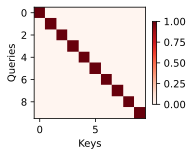

In [29]:
attention_weights = torch.eye(10).reshape((1, 1, 10, 10))
show_heatmaps(attention_weights, xlabel='Keys', ylabel='Queries')

## 10.2 注意力汇聚：Nadaraya-Watson 核回归


In [30]:
import torch
from torch import nn
from d2l import torch as d2l



### 10.2.1 生成数据集

使用一个非线性函数生成一个人工数据集

In [31]:
n_train = 50 # 训练样本数
x_train, _ = torch.sort(torch.rand(n_train) * 5) # 排序后的训练样本

def f(x):
    return 2 * torch.sin(x) + x ** 0.8  

y_train = f(x_train) + torch.normal(0.0, 0.5, (n_train,)) # 训练样本的标签
x_test = torch.arange(0, 5, 0.1) # 测试样本
y_truth = f(x_test) # 测试样本的真实输出
n_test = len(x_test) # 测试样本数
n_test
    

50

In [32]:
def plot_kernel_reg(y_hat):
    d2l.plot(x_test, [y_truth, y_hat], 'x', 'y', legend=['Truth', 'Pred'], xlim=[0, 5], ylim=[-1, 5])
    d2l.plt.plot(x_train, y_train, 'o', alpha=0.5)

### 

### 10.2.2 平均汇聚  
  
先使用最简单的估计器来解决回归问题。 基于平均汇聚来计算所有训练样本输出值的平均值：

$$f(x) = \frac{1}{n}\sum_{i=1}^n y_i$$

如下图所示，这个估计器确实不够聪明，真实函数f("Truth")和预测函数（“Pred”）相差很大。  
原因：完全不看 Query(即输入$x_i$)，直接计算所有 $y_i$ 的平均值。 Value 的权重完全相同，因此它不是根据 Query 动态分配权重的。

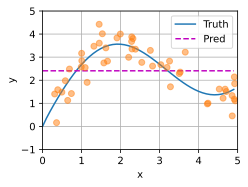

In [33]:
y_hat = torch.repeat_interleave(y_train.mean(), n_test)
plot_kernel_reg(y_hat)

### 10.2.3. 非参数注意力汇聚

平均汇聚忽略了输入$x_i$，更合理的方法是根据距离分配权重：  
Key 离 Query 越近，权重越大；  
Key 离 Query 越远，权重越小。  
采用根据输入的位置对输出$y_i$进行加权的方法：
$$f(x) = \sum_{i=1}^n \frac{K(x - x_i)}{\sum_{j=1}^n K(x - x_j)} y_i$$

上面这个公式名为Nadaraya-Watson核回归（Nadaraya-Watson kernel regression）。Nadaraya-Watson核回归是一个非参数模型。   
***K***是核（kernel,此处采用高斯核）：  

$$
K(x-x_i)=\exp\left(-\frac{(x-x_i)^2}{2}\right)
$$

 

于是预测结果为：
$$
\hat y=
\frac{\sum_iK(x-x_i)y_i}
{\sum_jK(x-x_j)}
$$ 
把权重单独写出来：  
$$
\alpha_i=
\frac{\exp\left(-\frac{(x-x_i)^2}{2}\right)}
{\sum_j\exp\left(-\frac{(x-x_j)^2}{2}\right)}
$$  
应该能看出，这其实就是 softmax：  
$$
\alpha_i=
\operatorname{softmax}
\left(-\frac{(x-x_i)^2}{2}\right)
$$  
最终：  
$$
\boxed{
\hat y=\sum_i\alpha_i y_i
}
$$  
这正是注意力机制的标准结构。  



注：   
其中评分函数 $-\frac{(x-x_i)^2}{2}$ ，前面带有负号，  
距离越小，分数越接近0；距离越大，分数越负。经过指数函数：
$$
e^0 > e^{-0.5} \gg e^{-8}
$$  
因此附近的 Key 得到更大的注意力权重。

In [1]:
# X_repeat 的形状：（n_test, n_train）,
# 每一行都包含着相同的测试输入（例如：同样的查询）
X_repeat = x_test.repeat_interleave(n_train).reshape((-1, n_train))
# x_train 包含着键。attention_weights 的形状：（n_test, n_train），
# 每一行都包含着要在给定的每个查询的值（y_train）之间分配的注意力权重

attention_weights = nn.functional.softmax(-(X_repeat - x_train) ** 2 / 2, dim=1)
#y_hat 的每个元素都是值的加权平均值， 其中的权重是注意力权重
y_hat = torch.matmul(attention_weights, y_train)
plot_kernel_reg(y_hat)

NameError: name 'x_test' is not defined

注意力的权重

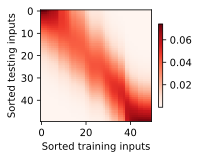

In [35]:
d2l.show_heatmaps(attention_weights.unsqueeze(0).unsqueeze(0), xlabel='Sorted training inputs', ylabel='Sorted testing inputs')

### 10.2.4 带参数注意力汇聚  
非参数的Nadaraya-Watson核回归具有一致性（consistency）的优点：如果有足够多的数据，此模型会收敛到最优结果。  
接下来将可学习参数集成到注意力汇聚中。    


参数 w 控制注意力范围：  
w 较大：距离被放大，注意力更集中，只参考很近的点；  
w 较小：距离差异被缩小，注意力更平缓，会参考更多点。    
  
模型通过训练自动决定应该“看多大范围”。  
这就是从非参数模型到可训练注意力模型的第一步。  


In [43]:
# define model
class NWKernelRegression(nn.Module):
    def __init__(self, **kwargs):
        super().__init__(**kwargs) # 调用父类的构造函数
        self.w = nn.Parameter(torch.rand((1, ), requires_grad = True))

    def forward(self, queries, keys, values):
        # queries 和 attention_weights 的形状为（查询个数，“键-值”对个数）
        queries = queries.repeat_interleave(keys.shape[1]).reshape((-1, keys.shape[1]))
        self.attention_weights = nn.functional.softmax(-((queries - keys)*self.w)**2 / 2, dim=1)
        #values 的形状为（查询个数，“键-值”对个数）
        return torch.bmm(self.attention_weights.unsqueeze(1), values.unsqueeze(-1)).reshape(-1)

In [44]:
# X_tile的形状:(n_train，n_train)，每一行都包含着相同的训练输入
X_tile = x_train.repeat((n_train, 1))
print(X_tile.shape)

# Y_tile的形状:(n_train，n_train)，每一行都包含着相同的训练输出
Y_tile = y_train.repeat((n_train, 1))  
print(Y_tile.shape)

# keys的形状:('n_train'，'n_train'-1)
keys = X_tile[(1 - torch.eye(n_train)).type(torch.bool)].reshape((n_train, -1))
print(keys.shape)

# values的形状:('n_train'，'n_train'-1)
values = Y_tile[(1 - torch.eye(n_train)).type(torch.bool)].reshape((n_train, -1))
print(values.shape)

torch.Size([50, 50])
torch.Size([50, 50])
torch.Size([50, 49])
torch.Size([50, 49])


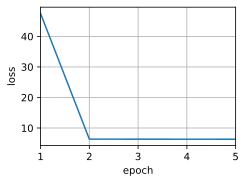

In [50]:
net = NWKernelRegression()
loss = nn.MSELoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=0.5)
animator = d2l.Animator(xlabel='epoch', ylabel='loss', xlim=[1, 5])

for epoch in range(5):
    trainer.zero_grad()
    l = loss(net(x_train, keys, values), y_train)
    l.sum().backward()
    trainer.step()
    print(f'epoch {epoch + 1}, loss {float(l.sum()):.6f}')
    animator.add(epoch + 1, float(l.sum()))

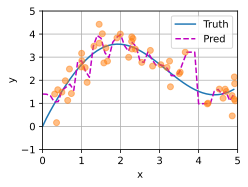

In [48]:
# keys的形状:(n_test，n_train)，每一行包含着相同的训练输入（例如，相同的键）
keys = x_train.repeat((n_test, 1))
# value的形状:(n_test，n_train)
values = y_train.repeat((n_test, 1))
y_hat = net(x_test, keys, values).unsqueeze(1).detach()
plot_kernel_reg(y_hat)



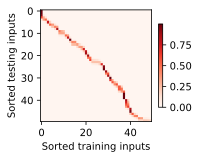

In [49]:
d2l.show_heatmaps(net.attention_weights.unsqueeze(0).unsqueeze(0),
                  xlabel='Sorted training inputs',
                  ylabel='Sorted testing inputs')

本节最重要的一些知识点：    
对照 Q、K、V  
核回归就是一个最简单的一维注意力模型：  
注意力概念|核回归中的对象
---------|----------------
Query|	要预测的位置 $x$
Key	|训练样本的位置 $x_i$
Value	|训练样本的标签 $y_i$
Score	|$-\frac12(x-x_i)^2$
Weight	|对 Score 做 softmax
Output	|$\sum_i\alpha_i y_i$


这张对应表是本节最重要的内容。

总结：  
Nadaraya-Watson 核回归并不是与 Transformer 无关的古老公式，它与tranformer 的softmax有相同骨架。

## 10.3 注意力评分

注意力评分函数：  
$$
a(q,k_i)=-\frac12(q-k_i)^2
$$

但这个公式只能处理非常简单的一维距离。真实模型中的 Query 和 Key 都是向量，因此需要更通用的评分方法。

- 掩蔽 softmax：由于一个批次中的句子长度通常不同，为了组成同一个张量，需要将较短的句子补齐，补齐后的形状相同了，但 <pad> 不包含任何真实信息。如果直接计算 softmax，模型可能会错误地给 <pad> 分配注意力。于是需要在 softmax 前把填充的这个位置的评分替换成一个极小的数。



- 加性注意力；
- 缩放点积注意力。

valid_lens 表示每个序列的有效长度：valid_lens = torch.tensor([2, 3])表示：  
第一个样本：前2个位置有效  
第二个样本：前3个位置有效